# GIS project: a step-by-step model comparison notebook

Each section explains one part of the workflow: setup, data and labels, preprocessing, model choice, training, checkpoint selection, validation metrics, plots, and export. The model-specific code is shared through one reusable training function, then run once per architecture.

The three models are ConvNeXtV2-Tiny, SwinV2-Tiny, and DINOv2 ViT-S/14. The notebook uses the maintained YOLO-label parser from src/satscene/labels.py; it does not use the old dummy-label approach. The test split is kept out of model selection.


## Step 1 — Connect Google Drive and prepare the project

Copy the SatScene project folder, including src/ and the dataset, into MyDrive/SatScene. This cell installs the notebook dependencies once and sets the project paths used by the later blocks.


In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = False
try:
    from google.colab import drive
    IN_COLAB = True
    drive.mount("/content/drive")
except ModuleNotFoundError:
    pass

candidates = []
if IN_COLAB:
    candidates.append(Path("/content/drive/MyDrive/SatScene"))
if os.environ.get("SATSCENE_PROJECT_DIR"):
    candidates.append(Path(os.environ["SATSCENE_PROJECT_DIR"]).expanduser())
candidates.extend([Path.cwd(), *Path.cwd().parents])

ROOT = next(
    (p.resolve() for p in candidates if (p / "src" / "satscene").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Open Jupyter from the SatScene project folder.")

os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
DATA_ROOT = ROOT / "data/Remote Sensing Data.v2i.yolov8"
print("Project:", ROOT)
print("Dataset:", DATA_ROOT)

Project: /Users/neuralnishan/HSE Education/Semester 1 /Geospatial Data Science 6 ECTS/_HA1/SatScene
Dataset: /Users/neuralnishan/HSE Education/Semester 1 /Geospatial Data Science 6 ECTS/_HA1/SatScene/data/Remote Sensing Data.v2i.yolov8


## Step 2 — Set shared experiment settings

The model list is defined in the next code block: ConvNeXtV2-Tiny, SwinV2-Tiny, and DINOv2 ViT-S/14. They cover modern convolutional, hierarchical-transformer, and self-supervised ViT backbones. All runs use the same seed, resolution, batch size, optimizer, epoch count, and validation checkpoint rule. Colab downloads their pretrained weights through timm. Reduce the batch size if the selected GPU runs out of memory.


In [2]:
import csv
import gc
import json
import random
import time
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import balanced_accuracy_score, f1_score
from torch import optim
from tqdm.auto import tqdm

from satscene.data import make_loader
from satscene.labels import class_distribution, collect_split, read_class_names
from satscene.model import build_model, load_checkpoint, save_checkpoint
from satscene.runtime import best_device

SEED = 42
IMG_SIZE = 256
BATCH_SIZE = 16
EPOCHS = 10
NUM_WORKERS = 2
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
DEVICE = best_device()
USE_AMP = DEVICE.type == 'cuda'

MODEL_RUNS = [
    {
        'name': 'convnextv2_tiny.fcmae_ft_in1k',
        'dir': ROOT / 'runs/convnextv2_tiny',
        'img_size': 224,
    },
    {
        'name': 'swinv2_tiny_window8_256.ms_in1k',
        'dir': ROOT / 'runs/swinv2_tiny_window8',
        'img_size': 256,
    },
    {
        'name': 'vit_small_patch14_dinov2.lvd142m',
        'dir': ROOT / 'runs/dinov2_vit_small_patch14',
        'img_size': 224,
    },
]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(
    f'Device: {DEVICE}; input size: {IMG_SIZE}; epochs: {EPOCHS}; '
    f'batch size: {BATCH_SIZE}'
)


/Users/neuralnishan/HSE Education/Semester 1 /Geospatial Data Science 6 ECTS/_HA1/SatScene/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps; input size: 256; epochs: 10; batch size: 16


## Step 3 — Read the dataset and check the labels

The dataset is an object-detection export. collect_split derives one scene label per image from its YOLO annotation (the most frequent class; ties use the first appearing class). Check class counts and skipped images before training so data issues are visible.


Classes: ['Agriculture', 'Airport', 'Beach', 'City', 'Desert', 'Forest', 'Grassland', 'Highway', 'Lake', 'Mountain', 'Parking', 'Port', 'Railway', 'River']
Train images: 700
Validation images: 200
Train class counts: {'Agriculture': 57, 'Airport': 47, 'Beach': 44, 'City': 118, 'Desert': 60, 'Forest': 64, 'Grassland': 60, 'Highway': 35, 'Lake': 28, 'Mountain': 51, 'Parking': 46, 'Port': 51, 'Railway': 22, 'River': 17}
Validation class counts: {'Agriculture': 15, 'Airport': 12, 'Beach': 9, 'City': 37, 'Desert': 16, 'Forest': 10, 'Grassland': 21, 'Highway': 11, 'Lake': 10, 'Mountain': 19, 'Parking': 14, 'Port': 9, 'Railway': 9, 'River': 8}
Skipped train images: 0
Skipped validation images: 0


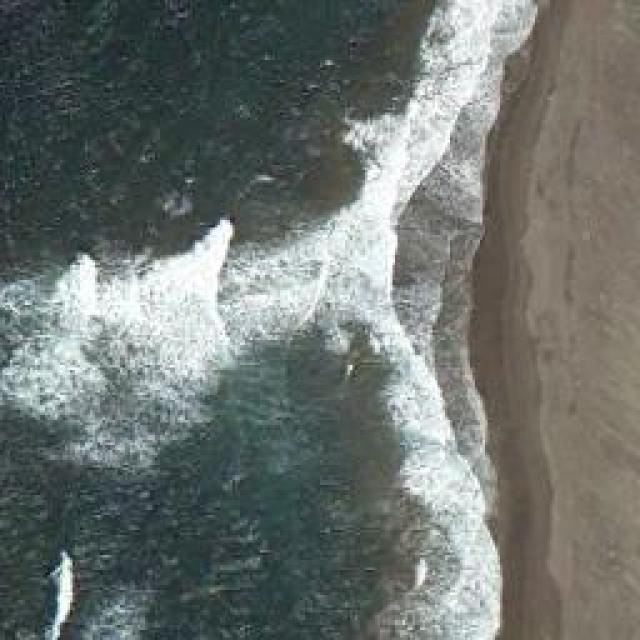

Derived label: Beach


In [3]:
assert (DATA_ROOT / 'data.yaml').is_file(), f'Missing dataset metadata: {DATA_ROOT / "data.yaml"}'

class_names = read_class_names(str(DATA_ROOT / 'data.yaml'))
train_ix = collect_split(str(DATA_ROOT), 'train')
val_ix = collect_split(str(DATA_ROOT), 'valid')

assert train_ix.paths and val_ix.paths, 'No labeled train or validation images found.'
print('Classes:', class_names)
print('Train images:', len(train_ix.paths))
print('Validation images:', len(val_ix.paths))
print('Train class counts:', class_distribution(train_ix.labels, class_names))
print('Validation class counts:', class_distribution(val_ix.labels, class_names))
print('Skipped train images:', len(train_ix.skipped))
print('Skipped validation images:', len(val_ix.skipped))

# Visual sanity check: inspect one image alongside its derived scene label.
from PIL import Image
from IPython.display import display
display(Image.open(train_ix.paths[0]))
print('Derived label:', class_names[train_ix.labels[0]])


## Step 4 — Build the shared image loaders

The maintained data module applies each model's configured input size and the same ImageNet normalization, with flips and 90-degree rotations for training images only. SwinV2 uses 256px for its window-8 stages; ConvNeXtV2 and DINOv2 use 224px. Validation preprocessing is deterministic.


In [4]:
train_loader = make_loader(
    train_ix.paths, train_ix.labels, IMG_SIZE, BATCH_SIZE,
    train=True, num_workers=NUM_WORKERS
)
val_loader = make_loader(
    val_ix.paths, val_ix.labels, IMG_SIZE, BATCH_SIZE,
    train=False, num_workers=NUM_WORKERS
)
print(f'Train batches: {len(train_loader)}; validation batches: {len(val_loader)}')


Train batches: 44; validation batches: 13


## Step 5 — Define the epoch-level validation pass

This block defines one prediction routine used by both checkpoint selection and the final report. During training it keeps only labels, predictions, and loss; Step 8 asks the same routine to retain probabilities for top-k and calibration metrics. The full report is rerun on the saved best checkpoint because it can come from an earlier epoch than the last one.


In [5]:
def predict_loader(model, loader, include_probabilities=False):
    """Run one shared validation pass and optionally retain class probabilities."""
    model.eval()
    loss_sum = 0.0
    y_true, y_pred = [], []
    probability_batches = [] if include_probabilities else None

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels_on_device = labels.to(DEVICE)
            logits = model(images)

            loss_sum += nn.functional.cross_entropy(
                logits, labels_on_device, reduction='sum'
            ).item()
            y_true.extend(labels.cpu().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().tolist())

            if include_probabilities:
                probability_batches.append(
                    torch.softmax(logits, dim=1).cpu().numpy()
                )

    count = len(y_true)
    result = {
        'y_true': np.asarray(y_true),
        'y_pred': np.asarray(y_pred),
        'loss': loss_sum / count,
        'probabilities': None,
    }
    if include_probabilities:
        result['probabilities'] = np.concatenate(probability_batches, axis=0)
    return result


def evaluate_epoch(model, loader):
    """Collect the lightweight scores needed to select a checkpoint."""
    output = predict_loader(model, loader)
    return {
        'val_loss': output['loss'],
        'val_acc': 100.0 * float(np.mean(output['y_true'] == output['y_pred'])),
        'val_macro_f1': f1_score(
            output['y_true'], output['y_pred'], average='macro', zero_division=0
        ),
        'val_balanced_acc': balanced_accuracy_score(
            output['y_true'], output['y_pred']
        ),
    }


## Step 6 — Define one reusable training function

Rather than copy a training loop three times, this function accepts one model specification. It writes that model's settings, epoch history, and best validation-macro-F1 weights into that model's own runs/ directory.


In [6]:
def train_one_model(spec):
    """Train one architecture and save its best validation macro-F1 checkpoint."""
    name = spec['name']
    run_dir = spec['dir']
    img_size = spec['img_size']
    run_dir.mkdir(parents=True, exist_ok=True)

    # Reset the seed so each model starts under the same random conditions.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    settings = {
        'model_name': name,
        'pretrained': True,
        'seed': SEED,
        'img_size': img_size,
        'epochs': EPOCHS,
        'batch_size': BATCH_SIZE,
        'learning_rate': LEARNING_RATE,
        'weight_decay': WEIGHT_DECAY,
        'selection_metric': 'val_macro_f1',
        'class_names': class_names,
        'data_root': str(DATA_ROOT),
    }
    (run_dir / 'config.json').write_text(json.dumps(settings, indent=2))

    if img_size == IMG_SIZE:
        model_train_loader, model_val_loader = train_loader, val_loader
    else:
        model_train_loader = make_loader(
            train_ix.paths, train_ix.labels, img_size, BATCH_SIZE,
            train=True, num_workers=NUM_WORKERS
        )
        model_val_loader = make_loader(
            val_ix.paths, val_ix.labels, img_size, BATCH_SIZE,
            train=False, num_workers=NUM_WORKERS
        )

    model = build_model(
        len(class_names), name, pretrained=True, img_size=img_size
    ).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    history = []
    best_score = float('-inf')
    best_epoch = 0
    start_time = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0.0
        total_images = 0

        for images, labels in tqdm(
            model_train_loader,
            desc=f'{name} · epoch {epoch}/{EPOCHS}',
            leave=False,
        ):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * len(labels)
            total_images += len(labels)

        row = {
            'epoch': epoch,
            'train_loss': total_loss / total_images,
            'lr': optimizer.param_groups[0]['lr'],
            **evaluate_epoch(model, model_val_loader),
        }
        history.append(row)
        scheduler.step()

        print(
            f'{name} | epoch {epoch}: '
            f'train loss={row["train_loss"]:.4f}, '
            f'validation accuracy={row["val_acc"]:.2f}%, '
            f'macro-F1={row["val_macro_f1"]:.4f}'
        )

        if row['val_macro_f1'] > best_score:
            best_score = row['val_macro_f1']
            best_epoch = epoch
            save_checkpoint(
                model,
                str(run_dir / 'best_model.pth'),
                class_names,
                name,
                img_size,
            )

    result = {
        'history': history,
        'best_epoch': best_epoch,
        'best_score': best_score,
        'selection_metric': 'val_macro_f1',
        'seconds': time.time() - start_time,
        'config': settings,
    }
    (run_dir / 'history.json').write_text(json.dumps(result, indent=2))

    del model, optimizer, scheduler, scaler
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f'Best checkpoint saved to {run_dir / "best_model.pth"}')
    return result


## Step 7 — Train the three models separately

Run the following three code cells in order. Each cell trains one model and stores its result in `RESULTS` for the evaluation and comparison cells below.


In [7]:
RESULTS = {}
RESULTS[MODEL_RUNS[0]['dir'].name] = train_one_model(MODEL_RUNS[0])

convnextv2_tiny.fcmae_ft_in1k | epoch 1: train loss=1.5476, validation accuracy=62.50%, macro-F1=0.5907


convnextv2_tiny.fcmae_ft_in1k | epoch 2: train loss=0.8320, validation accuracy=77.00%, macro-F1=0.7561


convnextv2_tiny.fcmae_ft_in1k | epoch 3: train loss=0.5395, validation accuracy=79.50%, macro-F1=0.7758


convnextv2_tiny.fcmae_ft_in1k | epoch 4: train loss=0.3444, validation accuracy=74.50%, macro-F1=0.7295


convnextv2_tiny.fcmae_ft_in1k | epoch 5: train loss=0.2088, validation accuracy=77.00%, macro-F1=0.7468


convnextv2_tiny.fcmae_ft_in1k | epoch 6: train loss=0.1157, validation accuracy=77.50%, macro-F1=0.7629


convnextv2_tiny.fcmae_ft_in1k | epoch 7: train loss=0.0720, validation accuracy=78.50%, macro-F1=0.7714


convnextv2_tiny.fcmae_ft_in1k | epoch 8: train loss=0.0456, validation accuracy=79.00%, macro-F1=0.7649


convnextv2_tiny.fcmae_ft_in1k | epoch 9: train loss=0.0338, validation accuracy=80.00%, macro-F1=0.7881


convnextv2_tiny.fcmae_ft_in1k | epoch 10: train loss=0.0287, validation accuracy=80.00%, macro-F1=0.7881
Best checkpoint saved to /Users/neuralnishan/HSE Education/Semester 1 /Geospatial Data Science 6 ECTS/_HA1/SatScene/runs/convnextv2_tiny/best_model.pth


In [8]:
RESULTS[MODEL_RUNS[1]['dir'].name] = train_one_model(MODEL_RUNS[1])

swinv2_tiny_window8_256.ms_in1k | epoch 1: train loss=1.9638, validation accuracy=47.50%, macro-F1=0.4234


swinv2_tiny_window8_256.ms_in1k | epoch 2: train loss=1.0914, validation accuracy=67.50%, macro-F1=0.6316


swinv2_tiny_window8_256.ms_in1k | epoch 3: train loss=0.7967, validation accuracy=69.00%, macro-F1=0.6646


swinv2_tiny_window8_256.ms_in1k | epoch 4: train loss=0.6347, validation accuracy=73.50%, macro-F1=0.7256


swinv2_tiny_window8_256.ms_in1k | epoch 5: train loss=0.4488, validation accuracy=73.50%, macro-F1=0.6976


swinv2_tiny_window8_256.ms_in1k | epoch 6: train loss=0.3646, validation accuracy=77.00%, macro-F1=0.7532


swinv2_tiny_window8_256.ms_in1k | epoch 7: train loss=0.1882, validation accuracy=73.00%, macro-F1=0.7032


swinv2_tiny_window8_256.ms_in1k | epoch 8: train loss=0.1352, validation accuracy=78.00%, macro-F1=0.7659


swinv2_tiny_window8_256.ms_in1k | epoch 9: train loss=0.0886, validation accuracy=78.00%, macro-F1=0.7665


swinv2_tiny_window8_256.ms_in1k | epoch 10: train loss=0.0585, validation accuracy=79.50%, macro-F1=0.7817
Best checkpoint saved to /Users/neuralnishan/HSE Education/Semester 1 /Geospatial Data Science 6 ECTS/_HA1/SatScene/runs/swinv2_tiny_window8/best_model.pth


In [9]:
RESULTS[MODEL_RUNS[2]['dir'].name] = train_one_model(MODEL_RUNS[2])

vit_small_patch14_dinov2.lvd142m | epoch 1: train loss=2.6807, validation accuracy=27.00%, macro-F1=0.0849


vit_small_patch14_dinov2.lvd142m | epoch 2: train loss=2.1949, validation accuracy=23.00%, macro-F1=0.1306


vit_small_patch14_dinov2.lvd142m | epoch 3: train loss=2.1243, validation accuracy=22.00%, macro-F1=0.1712


vit_small_patch14_dinov2.lvd142m | epoch 4: train loss=1.9213, validation accuracy=28.50%, macro-F1=0.2091


vit_small_patch14_dinov2.lvd142m | epoch 5: train loss=1.8341, validation accuracy=36.00%, macro-F1=0.2738


vit_small_patch14_dinov2.lvd142m | epoch 6: train loss=1.7922, validation accuracy=38.00%, macro-F1=0.2333


vit_small_patch14_dinov2.lvd142m | epoch 7: train loss=1.7117, validation accuracy=38.00%, macro-F1=0.2867


vit_small_patch14_dinov2.lvd142m | epoch 8: train loss=1.5750, validation accuracy=36.00%, macro-F1=0.2677


vit_small_patch14_dinov2.lvd142m | epoch 9: train loss=1.5284, validation accuracy=37.50%, macro-F1=0.2930


vit_small_patch14_dinov2.lvd142m | epoch 10: train loss=1.4213, validation accuracy=38.00%, macro-F1=0.3049
Best checkpoint saved to /Users/neuralnishan/HSE Education/Semester 1 /Geospatial Data Science 6 ECTS/_HA1/SatScene/runs/dinov2_vit_small_patch14/best_model.pth


## Step 8 — Compute the complete validation metrics

Reload each saved best checkpoint and use the shared prediction routine from Step 5. This pass retains class probabilities for calibration and top-k scores, then writes overall and per-class metrics, per-image predictions, confusion matrices, and diagnostics. It uses the validation split only; the test split remains untouched.


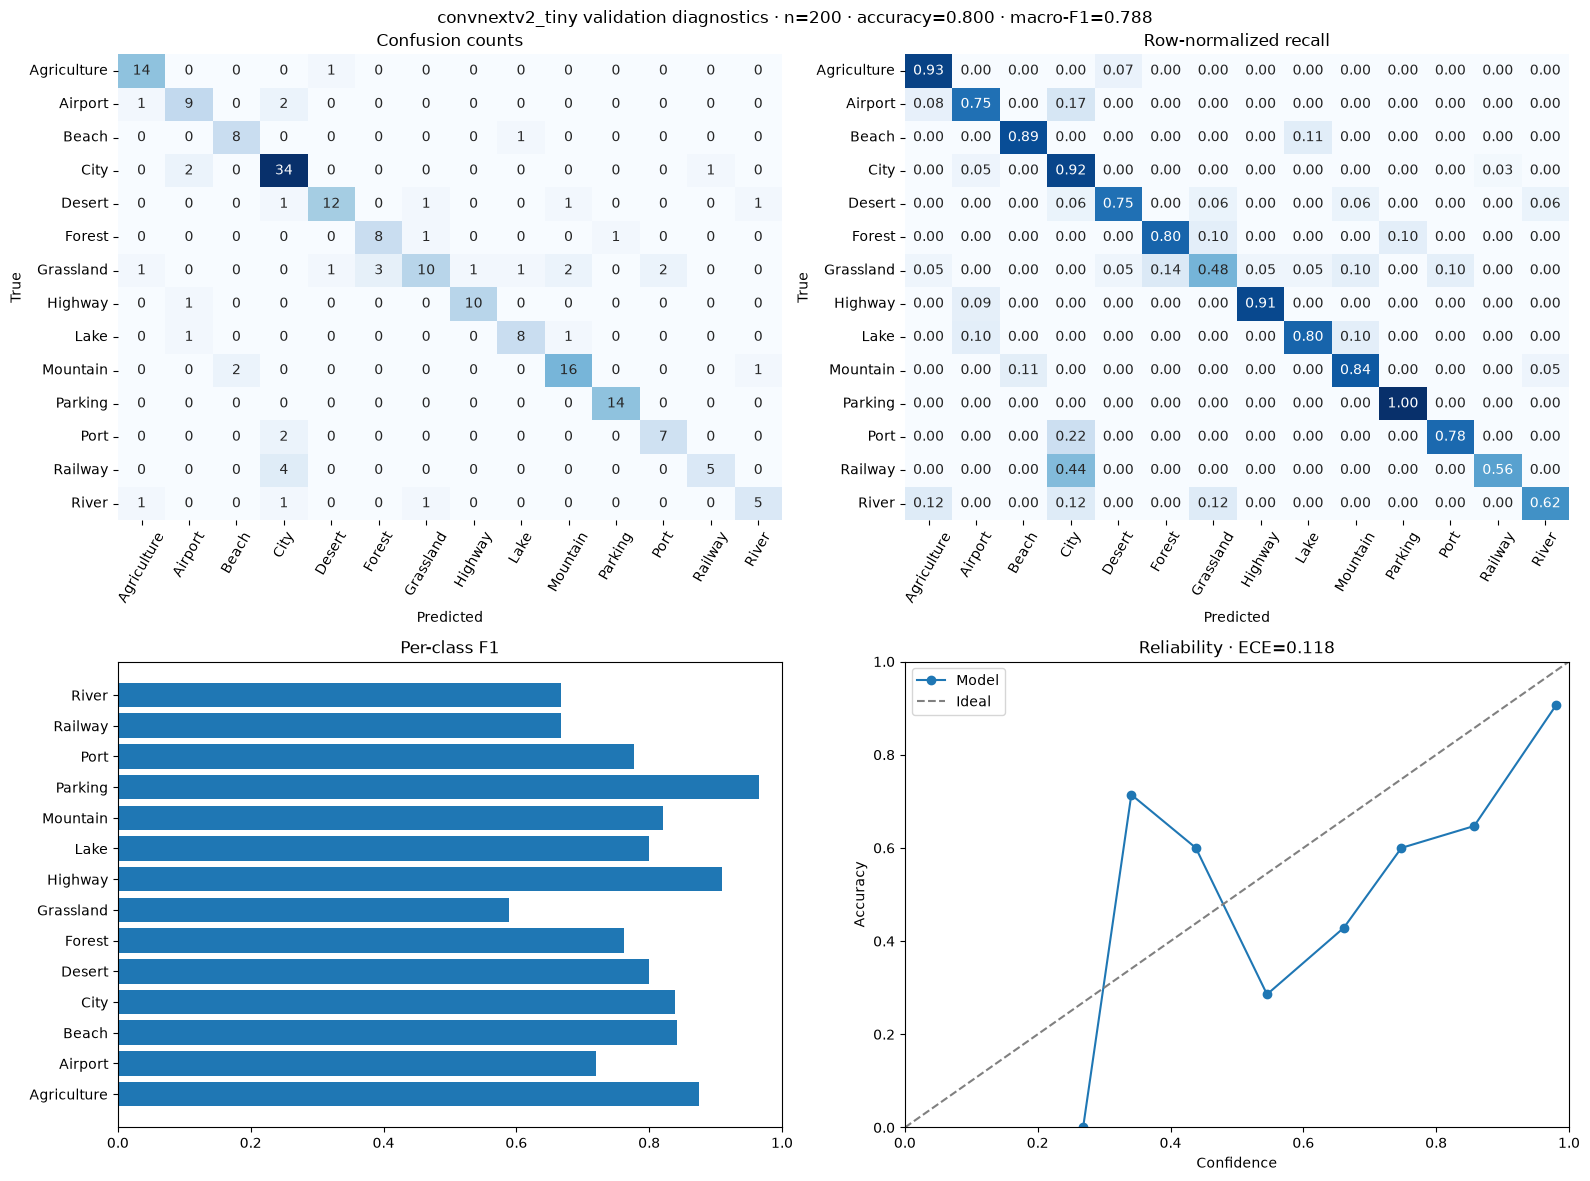

convnextv2_tiny: accuracy=0.800 (95% CI 0.739–0.850), macro-F1=0.788, balanced accuracy=0.788, top-3 accuracy=0.940, ECE=0.118


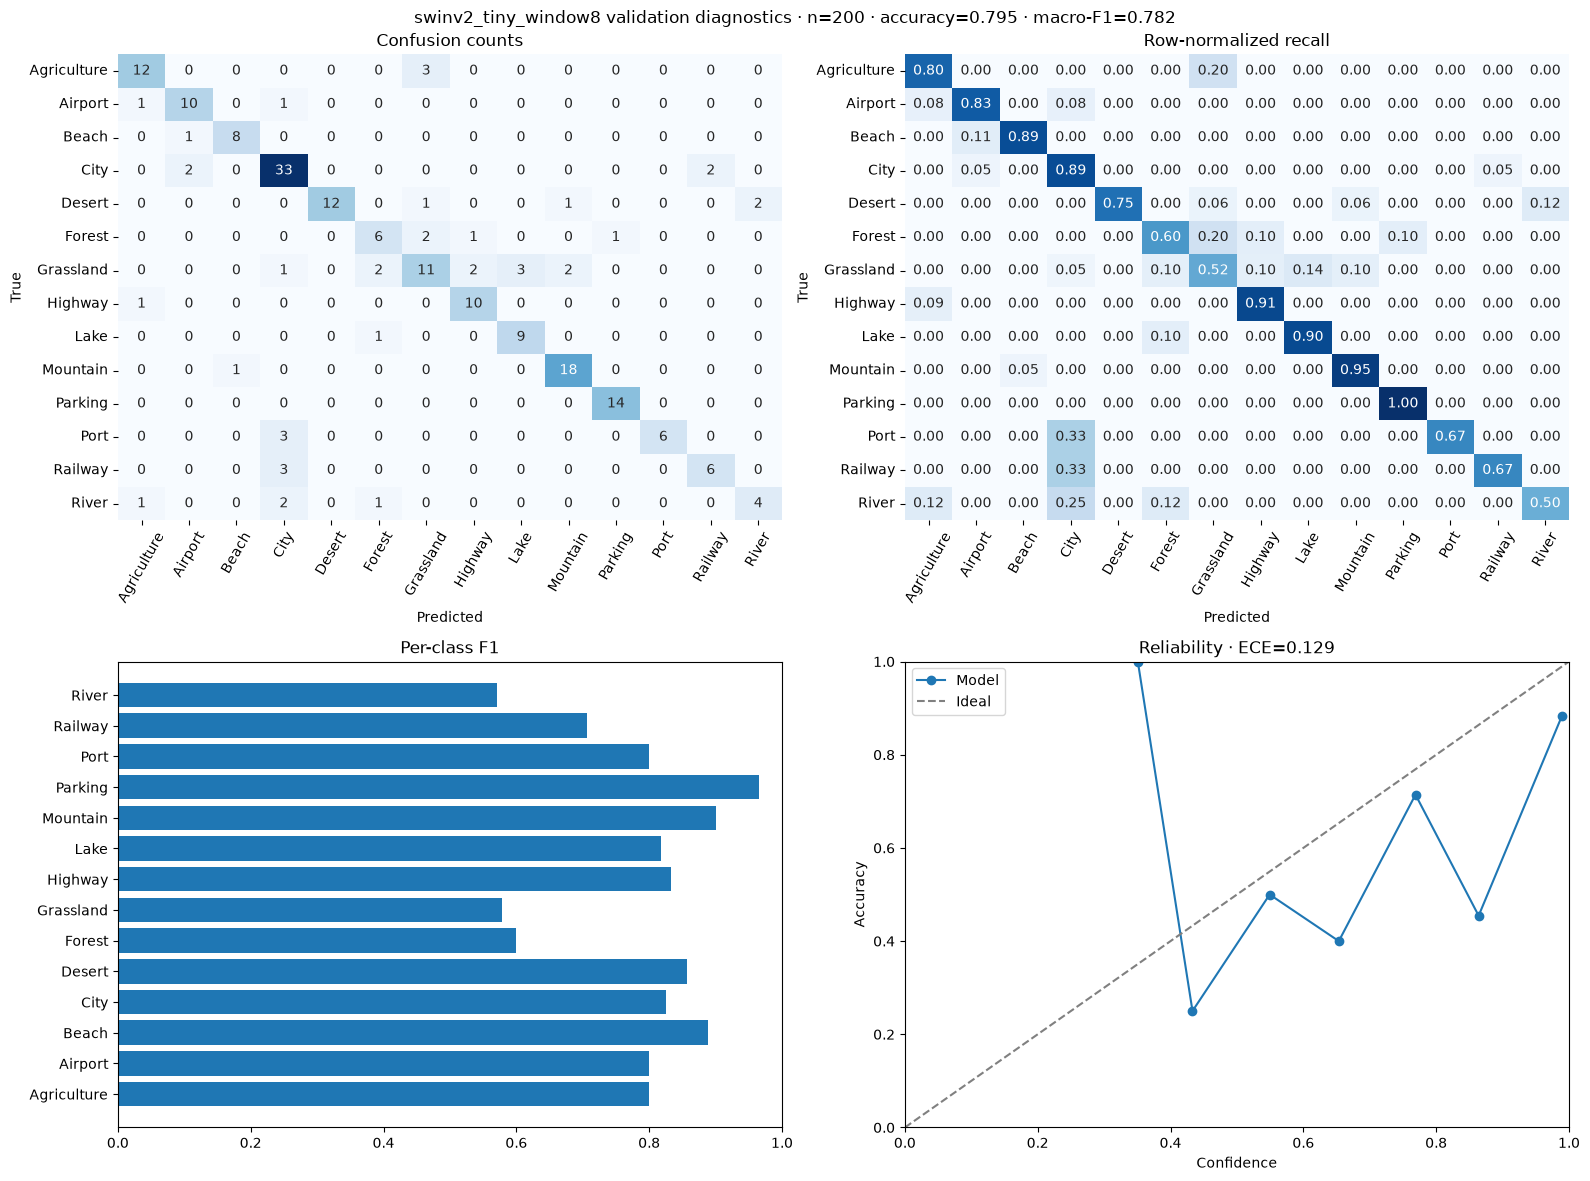

swinv2_tiny_window8: accuracy=0.795 (95% CI 0.734–0.845), macro-F1=0.782, balanced accuracy=0.777, top-3 accuracy=0.935, ECE=0.129


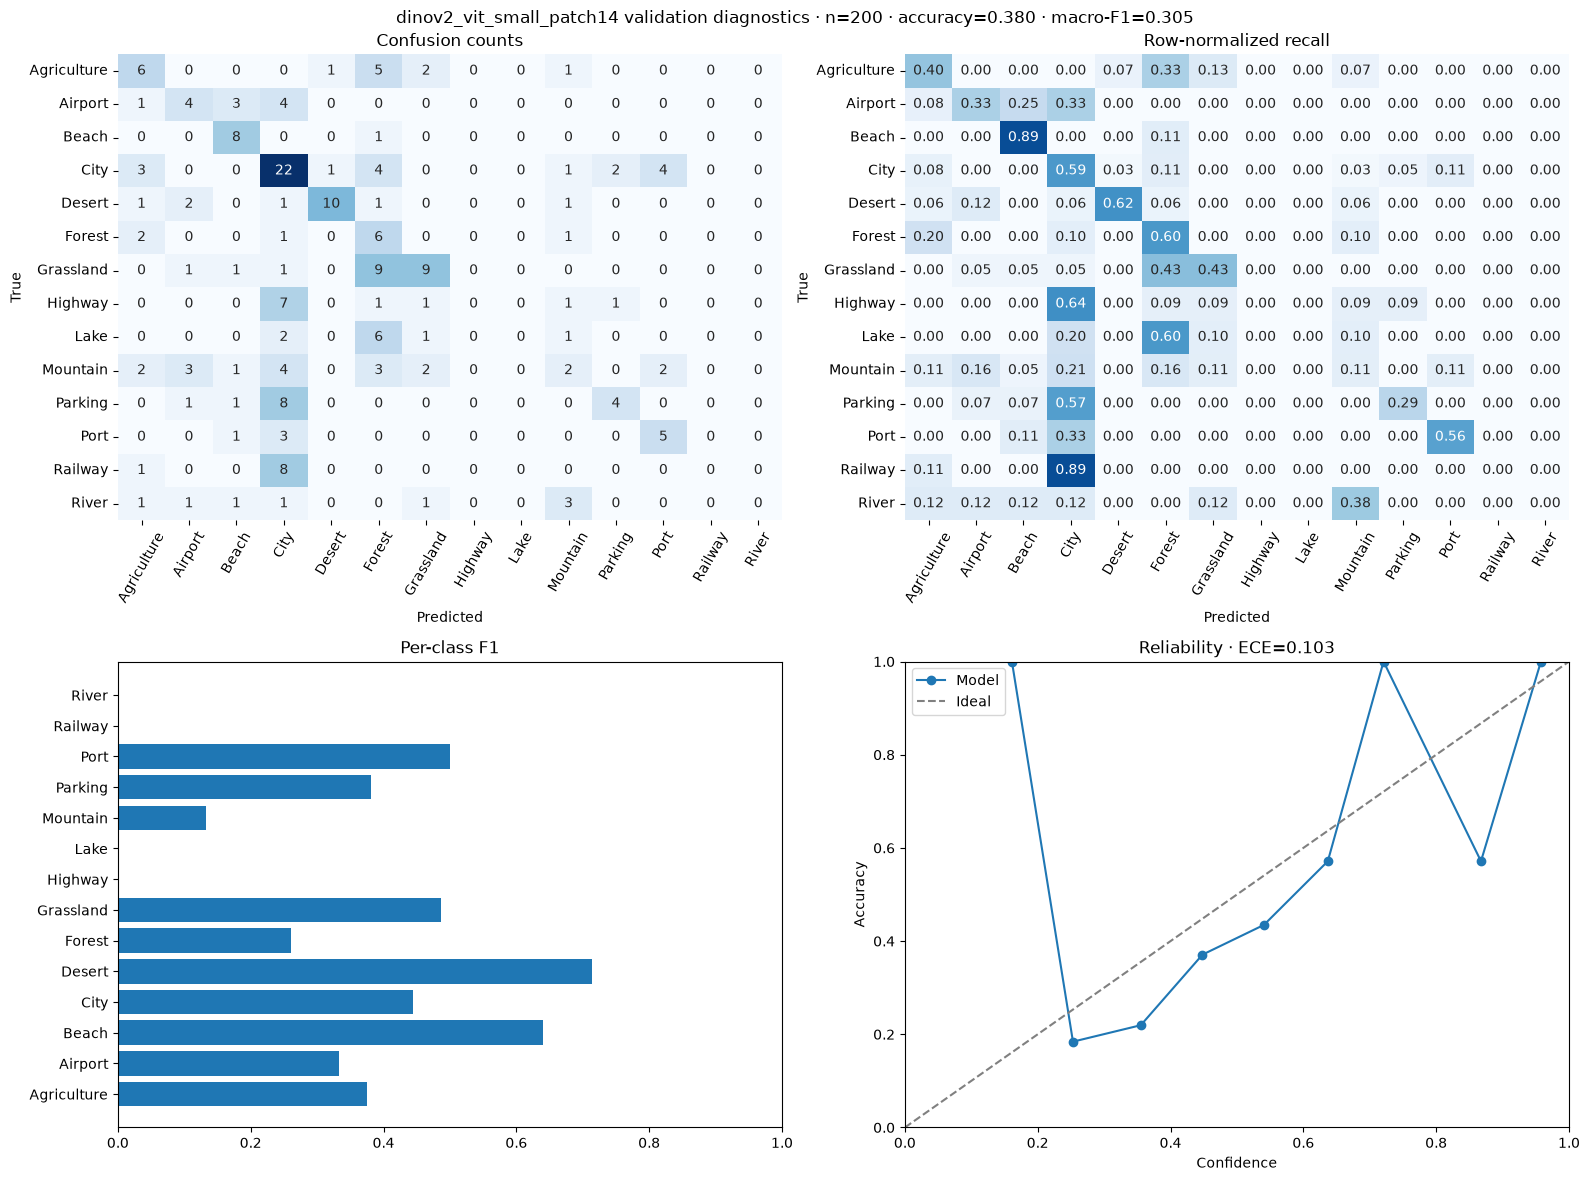

dinov2_vit_small_patch14: accuracy=0.380 (95% CI 0.316–0.449), macro-F1=0.305, balanced accuracy=0.344, top-3 accuracy=0.690, ECE=0.103
Saved the comparison CSV and each model’s validation reports and plots.


In [10]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from satscene.metrics import (
    calibration_summary,
    multiclass_brier_score,
    wilson_interval,
)

VALID_METRICS = {}
num_classes = len(class_names)
class_ids = list(range(num_classes))
top_k = min(3, num_classes)
top_k_key = f'top_{top_k}_accuracy'

for spec in MODEL_RUNS:
    name = spec['name']
    run_dir = spec['dir']
    img_size = spec['img_size']
    checkpoint_path = run_dir / 'best_model.pth'

    model_val_loader = val_loader if img_size == IMG_SIZE else make_loader(
        val_ix.paths, val_ix.labels, img_size, BATCH_SIZE,
        train=False, num_workers=NUM_WORKERS
    )
    model = build_model(
        num_classes, name, pretrained=False, img_size=img_size
    )
    model = load_checkpoint(model, str(checkpoint_path), DEVICE)

    # Reuse Step 5's prediction pass, retaining probabilities for calibration
    # and top-k metrics this time.
    output = predict_loader(model, model_val_loader, include_probabilities=True)
    y_true = output['y_true']
    y_pred = output['y_pred']
    probabilities = output['probabilities']
    count = len(y_true)
    correct = int(np.sum(y_true == y_pred))
    accuracy = correct / count
    accuracy_ci = wilson_interval(correct, count)

    class_precision, class_recall, class_f1, class_support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=class_ids,
            average=None,
            zero_division=0,
        )
    )
    per_class = {
        class_name: {
            'precision': float(class_precision[class_id]),
            'recall': float(class_recall[class_id]),
            'f1-score': float(class_f1[class_id]),
            'support': int(class_support[class_id]),
        }
        for class_id, class_name in enumerate(class_names)
    }

    averages = {}
    for average in ('macro', 'micro', 'weighted'):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average=average, zero_division=0
        )
        averages.update({
            f'{average}_precision': float(precision),
            f'{average}_recall': float(recall),
            f'{average}_f1': float(f1),
        })

    top_indices = np.argpartition(
        probabilities, -top_k, axis=1
    )[:, -top_k:]
    top_k_accuracy = float(
        np.mean(np.any(top_indices == y_true[:, None], axis=1))
    )
    calibration = calibration_summary(probabilities, y_true, bins=10)
    metrics = {
        'model': name,
        'split': 'valid',
        'n': count,
        'accuracy': accuracy,
        'accuracy_ci95': list(accuracy_ci),
        'cross_entropy_loss': output['loss'],
        'balanced_accuracy': float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        **averages,
        top_k_key: top_k_accuracy,
        'ece_top_label': calibration['ece'],
        'multiclass_brier_score': multiclass_brier_score(
            probabilities, y_true, num_classes
        ),
        'per_class': per_class,
        'calibration_bins': calibration['bins'],
    }
    VALID_METRICS[run_dir.name] = metrics
    (run_dir / 'metrics_valid.json').write_text(
        json.dumps(metrics, indent=2)
    )

    with (run_dir / 'per_class_metrics.csv').open('w', newline='') as file:
        writer = csv.DictWriter(
            file,
            fieldnames=['class', 'precision', 'recall', 'f1-score', 'support'],
        )
        writer.writeheader()
        for class_name, scores in per_class.items():
            writer.writerow({'class': class_name, **scores})

    with (run_dir / 'predictions_valid.csv').open('w', newline='') as file:
        writer = csv.DictWriter(
            file,
            fieldnames=[
                'image_path', 'true_class', 'predicted_class',
                'confidence', 'correct',
            ],
        )
        writer.writeheader()
        for image_path, truth, prediction, probabilities_row in zip(
            val_ix.paths, y_true, y_pred, probabilities
        ):
            writer.writerow({
                'image_path': image_path,
                'true_class': class_names[truth],
                'predicted_class': class_names[prediction],
                'confidence': float(probabilities_row[prediction]),
                'correct': bool(truth == prediction),
            })

    confusion_counts = confusion_matrix(
        y_true, y_pred, labels=class_ids
    )
    confusion_normalized = confusion_counts / np.maximum(
        confusion_counts.sum(axis=1, keepdims=True), 1
    )
    np.savetxt(
        run_dir / 'confusion_counts.csv', confusion_counts,
        delimiter=',', fmt='%d', header=','.join(class_names), comments='',
    )
    np.savetxt(
        run_dir / 'confusion_normalized.csv', confusion_normalized,
        delimiter=',', fmt='%.5f', header=','.join(class_names), comments='',
    )

    figure, axes = plt.subplots(2, 2, figsize=(16, 12))
    sns.heatmap(
        confusion_counts, annot=True, fmt='d', cmap='Blues',
        xticklabels=class_names, yticklabels=class_names,
        ax=axes[0, 0], cbar=False,
    )
    axes[0, 0].set_title('Confusion counts')
    sns.heatmap(
        confusion_normalized, annot=True, fmt='.2f', vmin=0, vmax=1,
        cmap='Blues', xticklabels=class_names, yticklabels=class_names,
        ax=axes[0, 1], cbar=False,
    )
    axes[0, 1].set_title('Row-normalized recall')
    for axis in axes[0]:
        axis.set_xlabel('Predicted')
        axis.set_ylabel('True')
        axis.tick_params(axis='x', rotation=60)
        axis.tick_params(axis='y', rotation=0)

    axes[1, 0].barh(
        class_names, [per_class[name]['f1-score'] for name in class_names]
    )
    axes[1, 0].set_xlim(0, 1)
    axes[1, 0].set_title('Per-class F1')
    axes[1, 1].plot(
        [item['confidence'] for item in calibration['bins']],
        [item['accuracy'] for item in calibration['bins']],
        'o-', label='Model',
    )
    axes[1, 1].plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
    axes[1, 1].set(
        xlim=(0, 1), ylim=(0, 1), xlabel='Confidence', ylabel='Accuracy',
        title=f"Reliability · ECE={calibration['ece']:.3f}",
    )
    axes[1, 1].legend()
    figure.suptitle(
        f'{run_dir.name} validation diagnostics · n={count} · '
        f'accuracy={accuracy:.3f} · macro-F1={averages["macro_f1"]:.3f}'
    )
    figure.tight_layout()
    figure.savefig(run_dir / 'validation_diagnostics.png', dpi=180)
    plt.show()
    plt.close(figure)

    print(
        f'{run_dir.name}: accuracy={accuracy:.3f} '
        f'(95% CI {accuracy_ci[0]:.3f}–{accuracy_ci[1]:.3f}), '
        f'macro-F1={averages["macro_f1"]:.3f}, '
        f'balanced accuracy={metrics["balanced_accuracy"]:.3f}, '
        f'top-{top_k} accuracy={top_k_accuracy:.3f}, '
        f'ECE={calibration["ece"]:.3f}'
    )

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

summary_keys = [
    'model', 'accuracy', 'accuracy_ci95', 'balanced_accuracy',
    'macro_precision', 'macro_recall', 'macro_f1', 'micro_f1',
    'weighted_f1', top_k_key, 'cross_entropy_loss', 'ece_top_label',
    'multiclass_brier_score',
]
comparison_path = ROOT / 'runs/model_comparison_metrics.csv'
with comparison_path.open('w', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=summary_keys)
    writer.writeheader()
    for result in sorted(
        VALID_METRICS.values(),
        key=lambda item: item['macro_f1'],
        reverse=True,
    ):
        writer.writerow({key: result[key] for key in summary_keys})

print('Saved the comparison CSV and each model’s validation reports and plots.')


## Step 9a — Compare the headline validation scores

This grouped chart shows accuracy, macro-F1, weighted-F1, balanced accuracy, and top-3 accuracy. The detailed numerical results remain in the CSV and per-model JSON reports.


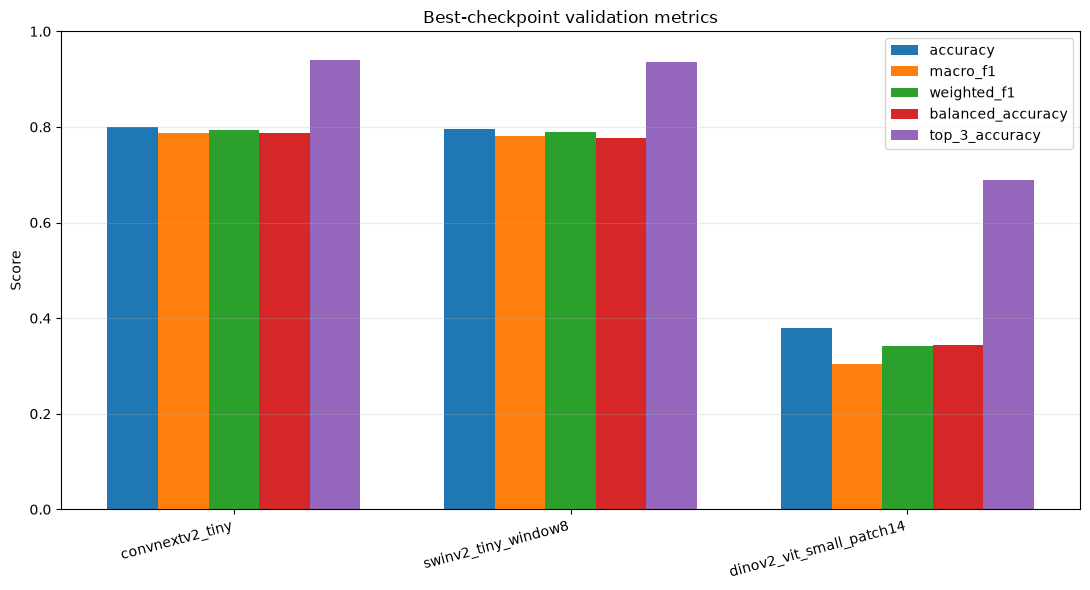

In [11]:
# Compare the main validation metrics from the detailed report.
metric_fields = [
    'accuracy', 'macro_f1', 'weighted_f1', 'balanced_accuracy', top_k_key,
]
model_names = list(VALID_METRICS)
positions = np.arange(len(model_names))
bar_width = 0.15

figure, axis = plt.subplots(figsize=(11, 6))
for metric_index, field in enumerate(metric_fields):
    offsets = positions + (metric_index - 2) * bar_width
    values = [VALID_METRICS[name][field] for name in model_names]
    axis.bar(offsets, values, bar_width, label=field)

axis.set_xticks(positions, model_names, rotation=15, ha='right')
axis.set_ylim(0, 1)
axis.set_ylabel('Score')
axis.set_title('Best-checkpoint validation metrics')
axis.grid(axis='y', alpha=0.25)
axis.legend()
figure.tight_layout()
figure.savefig(ROOT / 'runs/model_comparison_score_metrics.png', dpi=180)
plt.show()
plt.close(figure)


## Step 9b — Plot loss and validation accuracy across epochs

Save two separate comparison graphs: one for training loss and one for validation accuracy. Each graph has a line for every model and uses epoch on the x-axis. The best-checkpoint epoch is marked for reference.


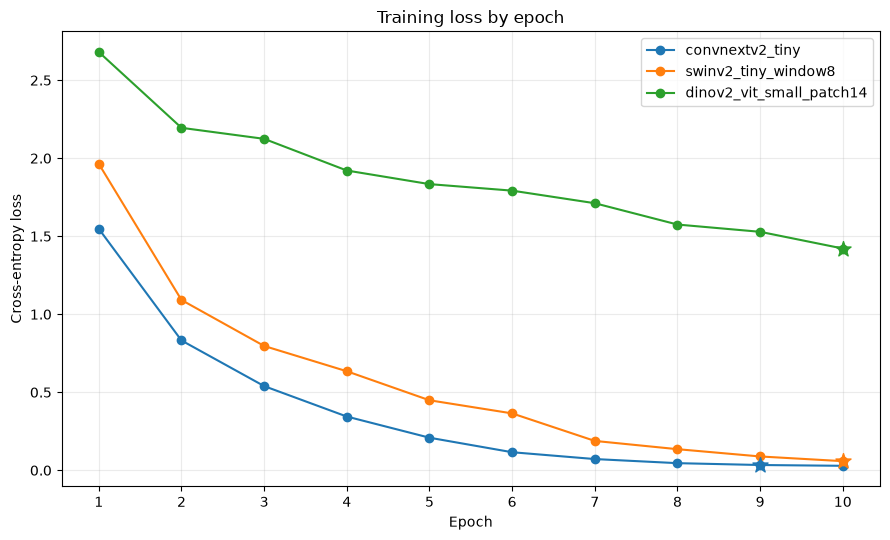

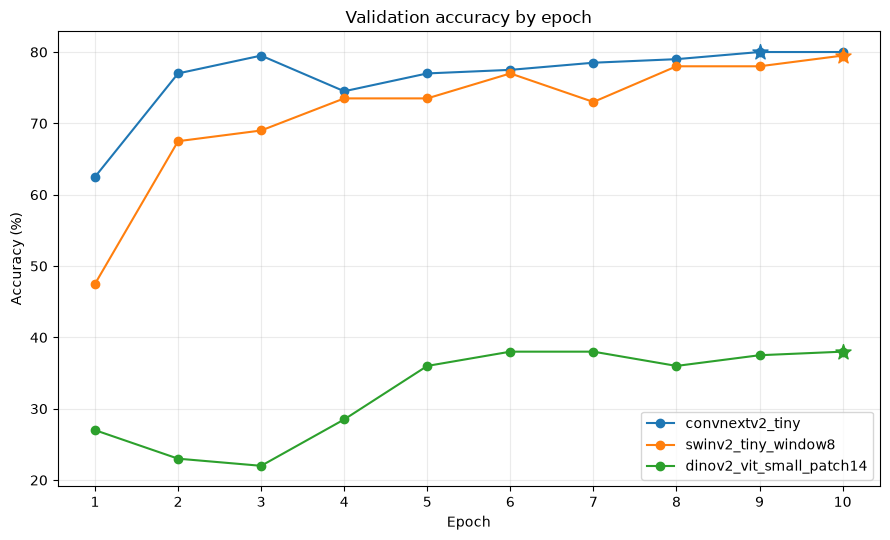

In [12]:
# Keep one comparison graph per requested quantity to avoid duplicate plots.
curve_specs = [
    (
        'train_loss',
        'Training loss by epoch',
        'Cross-entropy loss',
        'model_comparison_training_loss.png',
    ),
    (
        'val_acc',
        'Validation accuracy by epoch',
        'Accuracy (%)',
        'model_comparison_validation_accuracy.png',
    ),
]

for history_key, title, y_label, filename in curve_specs:
    figure, axis = plt.subplots(figsize=(9, 5.5))
    for spec in MODEL_RUNS:
        run_name = spec['dir'].name
        rows = RESULTS[run_name]['history']
        epochs = [row['epoch'] for row in rows]
        values = [row[history_key] for row in rows]
        best_epoch = RESULTS[run_name]['best_epoch']

        line, = axis.plot(epochs, values, 'o-', label=run_name)
        best_value = rows[best_epoch - 1][history_key]
        axis.scatter(
            [best_epoch], [best_value], marker='*', s=130,
            color=line.get_color(), zorder=5,
        )

    axis.set_title(title)
    axis.set_xlabel('Epoch')
    axis.set_ylabel(y_label)
    axis.set_xticks(range(1, EPOCHS + 1))
    axis.grid(alpha=0.25)
    axis.legend()
    figure.tight_layout()
    figure.savefig(ROOT / 'runs' / filename, dpi=180)
    plt.show()
    plt.close(figure)


## Step 10 — Review results, download artifacts, and run the local app

The ZIP contains each best checkpoint, settings and history, validation metrics, per-class and per-image CSVs, confusion matrices, and plots. Use validation results to choose a model; evaluate the held-out test split only once after model selection.

To run a downloaded checkpoint in the local app:

    python -m satscene.app --config configs/default.yaml --checkpoint runs/MODEL_RUN/best_model.pth


In [13]:
# Rank models by validation macro-F1 and package only these three run folders.
for spec in sorted(MODEL_RUNS,key=lambda x:RESULTS[x['dir'].name]['best_score'],reverse=True):
    result=RESULTS[spec['dir'].name]
    best=next(row for row in result['history'] if row['epoch']==result['best_epoch'])
    print(f"{spec['dir'].name}: epoch={result['best_epoch']}, "
          f"val_acc={best['val_acc']:.2f}%, val_macro_f1={best['val_macro_f1']:.4f}")

archive=ROOT/'satscene_three_model_runs.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as zf:
    for spec in MODEL_RUNS:
        for file in spec['dir'].rglob('*'):
            if file.is_file():
                zf.write(file,file.relative_to(ROOT))
    for file in [
        ROOT/'runs/model_comparison_training_loss.png',
        ROOT/'runs/model_comparison_validation_accuracy.png',
        ROOT/'runs/model_comparison_score_metrics.png',
        ROOT/'runs/model_comparison_metrics.csv',
    ]:
        zf.write(file,file.relative_to(ROOT))

from google.colab import files
files.download(str(archive))


convnextv2_tiny: epoch=9, val_acc=80.00%, val_macro_f1=0.7881
swinv2_tiny_window8: epoch=10, val_acc=79.50%, val_macro_f1=0.7817
dinov2_vit_small_patch14: epoch=10, val_acc=38.00%, val_macro_f1=0.3049


ModuleNotFoundError: No module named 'google.colab'